# INFO 2950-204 Final Project: Phase II
Richard Ballard · Josephine Kelly · Jason Choi · Orazio Petito

**Member contributions:**
- **Josie:** Notebook setup; session, driver, and Open-Meteo weather import and cleaning; initial questions and limitations.
- **Jason:** OpenF1 trackside weather pull (track temperature, rain); code comments and edits; typo fixes.
- **Richard:** Research questions, data description, and limitations; final data cleaning fixes and revisions; repo organization.
- **Orazio:** Preregistration statements and hypotheses; research question reframing; EDA and analysis-ready dataset; repo cleanup.

## Part 1: Data Collection and Exploratory Data Analysis

**Research question(s)**

Looking at F1 qualifying from 2023–2025, we want to know whether circuit conditions (mainly elevation, cloud cover, and temperature) affect teams differently once we look at relative pace instead of raw lap time.

More specifically:
1. Does elevation help some teams and hurt others relative to their usual pace?
2. Do certain teams look stronger than usual in cooler weather (and maybe under more cloud cover during day sessions) compared to other teams?

**Data description**

Inspired by Gebru et al. (2018), Datasheets for Datasets:

- **Observations (rows):** One row = one team in one qualifying session (2023–2025). **n = 870** (87 sessions × 10 teams). 18 of the 87 are sprint qualifying sessions (sprint weekends have two qualifying sessions); these are flagged with `is_sprint`.
- **Attributes (columns):** `session_key`, `year`, `circuit_short_name`, `session_name`, `is_sprint`, `team_name`, `date_start_est`, `local_hour`, `best_lap_s`, `pole_s`, `gap_to_pole_pct`, `season_avg_gap_pct`, `relative_pace`, `temperature_2m`, `cloud_cover`, `precipitation`, `track_temp`, `rain_any`, `elevation_m`, `is_night`, `is_mexico_city`, `is_mercedes`.
- **Why created:** To study whether weather and elevation change *team-relative* qualifying pace, not just who is fastest overall.
- **How created:** OpenF1 sessions/drivers/laps + Open-Meteo hourly weather at session start. Team best lap → % gap to pole → subtract that team’s season-average gap (= `relative_pace`). Circuit elevations joined by circuit name.
- **What influenced what was recorded:** OpenF1 covers 2023 onward; one qualifying session lacked lap data and was dropped. Weather is the hour of session start (EST), not minute-by-minute trackside sensors. Open-Meteo is reanalysis on an ~11–25 km grid.
- **Preprocessing:** Keep qualifying sessions (including sprint qualifying), drop cancelled sessions and 2026; exclude pit-out laps; aggregate to team-session; merge weather + elevation. Relative pace centered within team-year.
- **People:** Timing/weather are public motorsport/meteorology products; drivers are public figures in race broadcasts. No private survey data.
- **Raw sources:** [OpenF1](https://openf1.org/docs/), [Open-Meteo Historical API](https://open-meteo.com/en/docs/historical-weather-api). Raw API pulls are saved in the repo at [`data/raw/`](https://github.com/rbllrd/info2950-204_project/tree/main/data/raw); analysis-ready file: [`analysis_ready.csv`](https://github.com/rbllrd/info2950-204_project/blob/main/analysis_ready.csv).

OpenF1 gave us session times, teams, and qualifying laps. Open-Meteo filled in temperature, cloud cover, and related weather at each circuit’s coordinates for the session-start hour.


Circuit lat/long were looked up by `circuit_short_name`, then used to pull matching Open-Meteo hours.


**Data limitations**

- **Hourly weather:** Sessions last 1–2 hours; we only observe the start hour. Mid-session weather shifts (rain, cloud clearing) are missed and can misclassify conditions, weakening temperature/cloud associations.
- **Elevation is uneven:** A lot of tracks are pretty low; a couple are much higher. If we treat elevation as one continuous variable, those high tracks might pull the slope around, so we should also try the model without them.
- **Cars change within a season:** Season-average gap assumes a stable team baseline. Upgrades and driver swaps mean `relative_pace` mixes true condition effects with car development.
- **Air vs track temperature:** We use Open-Meteo `temperature_2m`, not rubbered-in track temp. Tire-grip claims (e.g. Mercedes in the cool) may be only partly captured.
- **Night races & cloud cover:** Clouds matter less at night for track heating; including night sessions can dilute cloud-cover effects unless we filter or add a day/night term.
- **Precipitation rarity:** Rain is zero for most sessions, so wet-weather effects would rest on a very small sample.
- **Coverage gaps:** OpenF1 starts in 2023; one qualifying session had no laps. Results generalize only to recent regulation eras.

**Questions for Reviewers (Part 1)**

- Teams change their cars during the season; how should we treat the full-season average? Or should we focus on individual races? What if these modifications were specifically formatted to compete in certain seasons?
- Should our research questions and/or preregistrations be more specific? We debated highlighting specific teams, drivers, or races, but were afraid of tightening our barriers too far.
- How negatively does the Open Meteo data being chunked by hour influence our data collection and integrity?
- How should we handle team renames or mid-season team changes for team drivers? We are focusing more generally on teams so perhaps we could ignore the individual drivers, but we are concerned about how individual driver performance and capabilities will influence our dataset and conclusions.

**Questions for Reviewers (Part 2)**
- Most tracks aren't that high, but one is (Mexico City). Is continuous elevation fine, or should we also compare high vs. low altitude tracks?
- Is it better to check by Q1 or better to check by a team's fastest lap and measure how far behind pole position it was? By checking with Q1, we obtain conditions close to equal for all drivers, but in exchange there are teams that may use used tires or one run to get through, making their Q1 gap distorted compared to their true pace, which would affect Mercedes in Statement 2. Otherwise, checking by pole position would also introduce distortion by comparing teams eliminated in Q1 against a faster Q3 track overall, biasing our outcomes in both analyses.

### Part 2: Preregistration of Analyses

**How we measure performance:** For each team at each qualifying session, we take the team's fastest lap of the whole session (faster of its two drivers) and measure how far behind the session's fastest lap (pole) it was, as a percentage. We then subtract the team's average gap for the season to get its relative pace. A negative value means the team was quicker than usual that weekend; a positive value means it was slower. This tells us whether conditions changed a team's performance, not just who's faster. (Teams knocked out in Q1 never run on the faster Q3 track, so their gaps are somewhat inflated; see our last question for reviewers.)
#### Preregistration Statement 1

**Hypothesis:** Elevation affects teams differently: some teams are relatively quicker on high-altitude circuits, while others are slower because of how their cars are built.

**Reasoning:** Air is thinner at high altitudes, which reduces downforce and makes cooling more difficult. Many teams design their cars around different trade-offs, so altitude should affect everyone differently. This could be due to the unique constructions of their cars, such as their downforce levels and cooling designs.

**Analysis:** We will run a linear regression with relative pace as the outcome and circuit elevation, team dummy variables, and elevation × team interaction terms as predictors, using Ferrari as the reference team. We will test whether the interaction terms are jointly zero with an F-test (comparing the model with and without the interactions), and report each interaction coefficient (testing whether it differs from 0). We'll also rerun it without Mexico City (the only track above 1,000 m), just to make sure one circuit isn't driving the whole elevation result.
#### Pre-registration Statement 2

**Hypothesis:** The Mercedes team specifically performs better than usual when the temperatures are cooler.

**Reasoning:** Tires only grip well within a certain temperature range. Mercedes' recent cars have struggled to keep their rear tires from overheating, and their recent wins (e.g. Las Vegas, Silverstone, Spa) came when temperatures dropped. In F1 news, the drivers have also been quoted being stressed about warmer temperatures for their performance.

**Analysis:** We will run a linear regression with relative pace as the outcome and air temperature (`temperature_2m`), the teams, and the interaction temperature × Mercedes. We’ll test whether that interaction is > 0 (Mercedes getting relatively worse as it gets hotter). We’ll also try the same setup with cloud cover instead of temperature, but only for daytime sessions, since cloud cover is less relevant at night.

#### Data cleaning

##### Libraries

In [30]:
# installing necessary libraries
%pip install -q seaborn pandas duckdb requests numpy

In [31]:
# loading necessary libraries and packages to handle our data
import requests # to extract from datasets
import pandas as pd # to handle the dataframes
import duckdb # to clean the data
from datetime import datetime # to handle the date time format

##### Race Session Import and Cleansing

In [32]:
# code OpenF1 API informs us to use to import
from urllib.request import urlopen
import json
response = urlopen('https://api.openf1.org/v1/sessions')
data = json.loads(response.read().decode('utf-8'))
temp_races_df = pd.DataFrame(data) # last line of provided code from API

For above code, this was provided by OpenF1 API in (https://openf1.org/docs) for information on how to import/scrape.

In [33]:
temp_races_df # checking the column headers
temp_races_df['session_type'].unique() # checking to see what the different types are to make sure we don't truncate

# selecting the wanted columns and races
races_df = duckdb.sql("SELECT session_key, session_type, session_name, date_start, date_end, circuit_short_name, country_name, location, year \
                      FROM temp_races_df WHERE ((session_type = 'Race' OR session_type = 'Qualifying') AND is_cancelled = False) \
                      AND year < 2026").df()
races_df # checking the product and modifying sql as necessary to prune canceled races and races from 2026 (ongoing) season
races_df['date_start'] = pd.to_datetime(races_df['date_start'], format='mixed') # reformat dates
races_df['date_end'] = pd.to_datetime(races_df['date_end'], format='mixed')
# wanting to uniform the time zone and make it more easily comprehensible for human reading
races_df['date_start'] = races_df['date_start'].dt.tz_convert("EST").dt.tz_localize(None)
races_df['date_end'] = races_df['date_end'].dt.tz_convert("EST").dt.tz_localize(None)
races_df # checking date time

,session_key,session_type,session_name,date_start,date_end,circuit_short_name,country_name,location,year
0,7768,Qualifying,Qualifying,2023-03-04 10:00:00,2023-03-04 11:00:00,Sakhir,Bahrain,Sakhir,2023
1,7953,Race,Race,2023-03-05 10:00:00,2023-03-05 12:00:00,Sakhir,Bahrain,Sakhir,2023
2,7775,Qualifying,Qualifying,2023-03-18 12:00:00,2023-03-18 13:00:00,Jeddah,Saudi Arabia,Jeddah,2023
3,7779,Race,Race,2023-03-19 12:00:00,2023-03-19 14:00:00,Jeddah,Saudi Arabia,Jeddah,2023
4,7783,Qualifying,Qualifying,2023-04-01 01:00:00,2023-04-01 02:00:00,Melbourne,Australia,Melbourne,2023
...,...,...,...,...,...,...,...,...,...
171,9845,Race,Sprint,2025-11-29 09:00:00,2025-11-29 10:00:00,Lusail,Qatar,Lusail,2025
172,9846,Qualifying,Qualifying,2025-11-29 13:00:00,2025-11-29 14:00:00,Lusail,Qatar,Lusail,2025
173,9850,Race,Race,2025-11-30 11:00:00,2025-11-30 13:00:00,Lusail,Qatar,Lusail,2025
174,9835,Qualifying,Qualifying,2025-12-06 09:00:00,2025-12-06 10:00:00,Yas Marina Circuit,United Arab Emirates,Yas Island,2025


Here, we have cleaned a DataFrame to contain the dates and times for races and the races that qualify the teams to participate in the larger race for narrowing down the time and date for the weather conditions. We also made sure to maintain the specific names of the locations to further assist us when looping in information from Open Meteo. We found the session types listed were `[Practice, Qualifying, Race]` and chose to disregard Practices since teams use these for practice and performance may not be up to par; in other words, since the teams are warming up or practicing on the track, the information consumed may not be as relevant to driver overall performance when representing their team name. One other important thing to note is that we filtered out the race dates from 2026. Since the 2026 F1 season is still ongoing, these races will lack information about the performance of teams and their drivers. We prefer to handle a constantly changing dataset, so we decided to stick with 2023, 2024, and 2025 where all the data is set.

##### Open F1 weather data

In [34]:
import time

quali_keys = duckdb.sql("SELECT session_key FROM races_df WHERE session_type = 'Qualifying'").df()['session_key']

weather_list = []
for key in quali_keys:
    response = urlopen(f'https://api.openf1.org/v1/weather?session_key={key}')
    weather_list.append(pd.DataFrame(json.loads(response.read().decode('utf-8'))))
    print(key)
    time.sleep(2.1)
temp_f1_weather_df = pd.concat(weather_list, ignore_index=True)

# we should convert to naive EST so it matches races_df
temp_f1_weather_df['date'] = pd.to_datetime(temp_f1_weather_df['date'], format='mixed').dt.tz_convert("EST").dt.tz_localize(None)

7768
7775
7783
9064
9278
9074
9090
9098
9106
9112
9282
9122
9129
9135
9286
9145
9153
9161
9169
9215
9298
9207
9294
9177
9304
9308
9314
9193
9468
9476
9484
9492
9668
9664
9502
9498
9511
9519
9527
9535
9545
9541
9554
9562
9570
9578
9586
9594
9602
9612
9608
9621
9631
9627
9640
9650
9646
9658
9689
9989
9994
10002
10010
10018
10024
10029
9983
9975
9967
9959
9951
9943
9930
9935
9924
9916
9908
9900
9892
9879
9884
9873
9860
9865
9854
9841
9846
9835


Here, we pull weather information from OpenF1's weather endpoint (https://openf1.org/docs/#weather). Unlike Open Meteo, OpenF1 records weather directly at the track about once every minute, including track temperature, which Open Meteo does not have. We use it to check our Open-Meteo air temperature (track temperature is closer to what the tires feel) and to flag rainy sessions. We looped through every qualifying session key and pulled its weather readings one at a time, with a 2.1-second pause between requests to stay within OpenF1's rate limit (time.sleep(0.5) proved too much for the server). We then convert the dates to EST so they match the data in races_df, which is also in EST, and print(key) lets us track progress.

In [35]:
f1_weather_df = duckdb.sql("SELECT weather.session_key, AVG(weather.track_temperature) AS track_temp, AVG(weather.air_temperature) AS air_temp_f1, \
                           AVG(weather.humidity) AS humidity, MAX(weather.rainfall) > 0 AS rain_any, COUNT(*) AS n_readings \
                           FROM temp_f1_weather_df weather JOIN races_df races ON weather.session_key = races.session_key \
                           WHERE weather.date BETWEEN races.date_start AND races.date_end GROUP BY weather.session_key").df()
f1_weather_df #weathers
print(f1_weather_df)

    session_key  track_temp  air_temp_f1   humidity  rain_any  n_readings
0          7768   28.210000    23.993333  19.116667     False          60
1          7775   31.575000    27.060000  43.750000     False          60
2          9064   33.643333    19.413333  80.483333     False          60
3          9278   48.359091    24.388636  67.318182     False          44
4          9074   43.045000    28.673333  59.516667     False          60
..          ...         ...          ...        ...       ...         ...
83         9908   42.575000    26.651667  35.883333     False          60
84         9892   34.931667    29.861667  69.200000     False          60
85         9873   45.695000    26.218333  27.466667     False          60
86         9865   39.706667    25.951667  56.783333     False          60
87         9854   12.540000    11.740000  65.283333      True          60

[88 rows x 6 columns]


We narrow the weather readings down to only those taken during each qualifying session by keeping readings between the session’s start and end times. We then averaged the track temperature, air temperature, and humidity so that each session has one set of weather values. We also marked a session as rainy if any reading during it showed rainfall, since we plan to specially allocate wet sessions from our analyses. Lastly, we counted how many readings went into each average; since readings come about once a minute, a one-hour session should have around 60, which helps us check that the times lined up correctly between one race and another.

##### Drivers and Their Teams Import and Cleansing

In [36]:
# code OpenF1 API informs us to use to import
response = urlopen('https://api.openf1.org/v1/drivers')
data = json.loads(response.read().decode('utf-8'))
temp_drivers_df = pd.DataFrame(data) # last line of provided code from API

For above code, this was provided by OpenF1 API in (https://openf1.org/docs) for information on how to import/scrape.

In [37]:
temp_drivers_df # checking the column headers
temp_drivers_df['broadcast_name'].unique() # seeing who is really driver because original is 10k lines

drivers_df = duckdb.sql("SELECT DISTINCT r.year, d.driver_number, d.full_name, d.name_acronym, d.team_name, d.country_code \
                      FROM temp_drivers_df d JOIN races_df r ON r.session_key = d.session_key ORDER BY d.full_name, d.team_name, r.year").df()
drivers_df

,year,driver_number,full_name,name_acronym,team_name,country_code
0,2023,23,Alexander ALBON,ALB,Williams,THA
1,2024,23,Alexander ALBON,ALB,Williams,THA
2,2025,23,Alexander ALBON,ALB,Williams,None
3,2023,55,Carlos SAINZ,SAI,Ferrari,ESP
4,2024,55,Carlos SAINZ,SAI,Ferrari,ESP
...,...,...,...,...,...,...
65,2024,22,Yuki TSUNODA,TSU,RB,JPN
66,2025,22,Yuki TSUNODA,TSU,Racing Bulls,None
67,2025,22,Yuki TSUNODA,TSU,Red Bull Racing,None
68,2023,24,ZHOU Guanyu,ZHO,Alfa Romeo,CHN


Here, we have cleaned a DataFrame to contain the names, team names, years, and countries of the drivers. One thing that makes this dataset difficult to handle is how the same driver might have different driver numbers or teams or country associations year to year. This is something we will have to deal with as we analyze the data. I decided to join the race date information to help add understanding to the team associations. Since team associations might shift year to year, this helps narrow it down. Additionally, joining on the session keys helps ensure we aren't including information from practices since the session keys from `races_df` would be pruned down by date, race cancellation, etc. We choose to focus on `session_key` and not `meeting_key` since `meeting_key` is specific to special meets and chunks entire weekends together. `session_key` keeps each individual track session separate, which is far more specific.

##### Weather Information Import and Cleansing

In [38]:
races_df['circuit_short_name'].unique() # to print out the entire full list of circuit names scrollable

# research each circuit name for latitude and longitude
circuit_coords = {
    # OpenF1 circuit_short_name: (latitude, longitude) # full name
    "Sakhir": (26.0325, 50.5106),   # Bahrain International Circuit
    "Jeddah": (21.6319, 39.1044),   # Jeddah Corniche Circuit
    "Melbourne": (-37.8497, 144.9680),   # Albert Park
    "Baku": (40.3725, 49.8533),   # Baku City Circuit
    "Miami": (25.9581, -80.2389),   # Miami International Autodrome
    "Monte Carlo": (43.7347, 7.4206),   # Circuit de Monaco
    "Catalunya": (41.5700, 2.2611),   # Circuit de Barcelona-Catalunya
    "Montreal": (45.5017, -73.5228),   # Circuit Gilles Villeneuve
    "Spielberg": (47.2197, 14.7647),   # Red Bull Ring
    "Silverstone": (52.0786, -1.0169),   # Silverstone Circuit
    "Hungaroring": (47.5789, 19.2486),   # Hungaroring
    "Spa-Francorchamps": (50.4372, 5.9714),   # Circuit de Spa-Francorchamps
    "Zandvoort": (52.3888, 4.5409),   # Circuit Zandvoort
    "Monza": (45.6156, 9.2811),   # Autodromo Nazionale Monza
    "Singapore": (1.2914, 103.8640),   # Marina Bay Street Circuit
    "Suzuka": (34.8431, 136.5410),   # Suzuka International Racing Course
    "Lusail": (25.4900, 51.4542),   # Lusail International Circuit
    "Austin": (30.1328, -97.6411),   # Circuit of the Americas
    "Mexico City": (19.4042, -99.0907),   # Autódromo Hermanos Rodríguez
    "Interlagos": (-23.7036, -46.6997),   # Autódromo José Carlos Pace
    "Las Vegas": (36.1147, -115.1728),   # Las Vegas Strip Circuit
    "Yas Marina Circuit": (24.4672, 54.6031),   # Yas Marina Circuit
    "Shanghai": (31.3389, 121.2197),   # Shanghai International Circuit
    "Imola": (44.3439, 11.7167),   # Autodromo Enzo e Dino Ferrari
}

coords_df = pd.DataFrame.from_dict(circuit_coords, orient='index', columns=['latitude', 'longitude']).rename_axis("circuit_short_name").reset_index()
coords_df # ensure it looks correct

# prepping one Open Meteo request per qualifying session; session_key stays on every row so dates and circuits can't get mixed up
quali_df = races_df[races_df['session_type'] == 'Qualifying'].copy()
quali_df['is_sprint'] = quali_df['session_name'] != 'Qualifying' # Sprint Shootout (2023) / Sprint Qualifying (2024-25)
openmeteo_input_df = quali_df[['session_key', 'circuit_short_name', 'date_start']].merge(coords_df, on='circuit_short_name')
openmeteo_input_df['date'] = openmeteo_input_df['date_start'].dt.strftime("%Y-%m-%d") # EST date of the session
openmeteo_input_df['hour'] = openmeteo_input_df['date_start'].dt.hour # EST hour the session started
openmeteo_input_df.to_csv('openmeteo_input.csv', index=False) # save intermediate file
openmeteo_input_df # print to see if format good

,session_key,circuit_short_name,date_start,latitude,longitude,date,hour
0,7768,Sakhir,2023-03-04 10:00:00,26.0325,50.5106,2023-03-04,10
1,7775,Jeddah,2023-03-18 12:00:00,21.6319,39.1044,2023-03-18,12
2,7783,Melbourne,2023-04-01 01:00:00,-37.8497,144.9680,2023-04-01,1
3,9064,Baku,2023-04-28 08:00:00,40.3725,49.8533,2023-04-28,8
4,9278,Baku,2023-04-29 03:30:00,40.3725,49.8533,2023-04-29,3
...,...,...,...,...,...,...,...
83,9865,Interlagos,2025-11-08 13:00:00,-23.7036,-46.6997,2025-11-08,13
84,9854,Las Vegas,2025-11-21 23:00:00,36.1147,-115.1728,2025-11-21,23
85,9841,Lusail,2025-11-28 12:30:00,25.4900,51.4542,2025-11-28,12
86,9846,Lusail,2025-11-29 13:00:00,25.4900,51.4542,2025-11-29,13


Above, we modified our existing datasets and information to be able to input it to Open Meteo more easily.

In [39]:
# code provided to us to input for importing data by the Open Meteo website
%pip install -q openmeteo-requests
%pip install -q requests-cache retry-requests numpy pandas

import openmeteo_requests
import requests_cache
from retry_requests import retry

# Setup the Open-Meteo API client with cache and retry on error
cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
openmeteo = openmeteo_requests.Client(session = retry_session)

In [40]:
# Make sure all required weather variables are listed here
# The order of variables in hourly or daily is important to assign them correctly below
def openmeteo_pull(lat, long, start, end, spec_hour):
	url = "https://archive-api.open-meteo.com/v1/archive"
	params = {
		"latitude": [lat],
		"longitude": [long],
		"start_date": [start],
		"end_date": [end],
		"hourly": ["temperature_2m", "precipitation", "cloud_cover_low", "cloud_cover_high", "cloud_cover_mid", "cloud_cover", "surface_pressure", "wind_speed_10m", "wind_direction_10m", "wind_gusts_10m", "wind_direction_100m", "wind_speed_100m"],
		"timezone": ["EST"],
	}
	responses = openmeteo.weather_api(url, params = params)

	# Process 8 locations
	for response in responses:
		#print(f"\nCoordinates: {response.Latitude()}°N {response.Longitude()}°E")
		#print(f"Elevation: {response.Elevation()} m asl")
		#print(f"Timezone: {response.Timezone()}{response.TimezoneAbbreviation()}")
		#print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")

		# Process hourly data. The order of variables needs to be the same as requested.
		hourly = response.Hourly()
		hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
		hourly_precipitation = hourly.Variables(1).ValuesAsNumpy()
		hourly_cloud_cover_low = hourly.Variables(2).ValuesAsNumpy()
		hourly_cloud_cover_high = hourly.Variables(3).ValuesAsNumpy()
		hourly_cloud_cover_mid = hourly.Variables(4).ValuesAsNumpy()
		hourly_cloud_cover = hourly.Variables(5).ValuesAsNumpy()
		hourly_surface_pressure = hourly.Variables(6).ValuesAsNumpy()
		hourly_wind_speed_10m = hourly.Variables(7).ValuesAsNumpy()
		hourly_wind_direction_10m = hourly.Variables(8).ValuesAsNumpy()
		hourly_wind_gusts_10m = hourly.Variables(9).ValuesAsNumpy()
		hourly_wind_direction_100m = hourly.Variables(10).ValuesAsNumpy()
		hourly_wind_speed_100m = hourly.Variables(11).ValuesAsNumpy()

		hourly_data = {
			"date": pd.date_range(
				start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
				end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
				freq = pd.Timedelta(seconds = hourly.Interval()),
				inclusive = "left"
			).tz_convert(response.Timezone().decode())
		}

		mask = (hourly_data['date'].hour == spec_hour)

		hourly_data["date"] = hourly_data["date"][mask]

		hourly_data["temperature_2m"] = hourly_temperature_2m[mask]
		hourly_data["precipitation"] = hourly_precipitation[mask]
		hourly_data["cloud_cover_low"] = hourly_cloud_cover_low[mask]
		hourly_data["cloud_cover_high"] = hourly_cloud_cover_high[mask]
		hourly_data["cloud_cover_mid"] = hourly_cloud_cover_mid[mask]
		hourly_data["cloud_cover"] = hourly_cloud_cover[mask]
		hourly_data["surface_pressure"] = hourly_surface_pressure[mask]
		hourly_data["wind_speed_10m"] = hourly_wind_speed_10m[mask]
		hourly_data["wind_direction_10m"] = hourly_wind_direction_10m[mask]
		hourly_data["wind_gusts_10m"] = hourly_wind_gusts_10m[mask]
		hourly_data["wind_direction_100m"] = hourly_wind_direction_100m[mask]
		hourly_data["wind_speed_100m"] = hourly_wind_speed_100m[mask]

		hourly_dataframe = pd.DataFrame(data = hourly_data)
		return hourly_dataframe
		# print("\nHour data\n", hourly_dataframe)

weather_list = []
# go through every qualifying session and pull the weather for the hour it started
for value in openmeteo_input_df.itertuples():
	hour_df = openmeteo_pull(value.latitude, value.longitude, value.date, value.date, int(value.hour))
	hour_df['session_key'] = value.session_key # tag the weather row with its session
	weather_list.append(hour_df)
weather_df = pd.concat(weather_list, ignore_index=True)

weather_df['date'] = weather_df['date'].dt.tz_localize(None) # reformat date to match our other date columns
weather_df

,date,temperature_2m,precipitation,cloud_cover_low,cloud_cover_high,cloud_cover_mid,cloud_cover,surface_pressure,wind_speed_10m,wind_direction_10m,wind_gusts_10m,wind_direction_100m,wind_speed_100m,session_key
0,2023-03-04 10:00:00,23.250000,0.0,0.0,0.0,0.0,0.0,1017.361511,12.605142,88.363464,24.119999,89.045181,21.602999,7768
1,2023-03-18 12:00:00,25.886999,0.0,0.0,39.0,0.0,39.0,1010.469238,18.250259,337.988647,29.879999,338.838654,23.933907,7775
2,2023-04-01 01:00:00,14.500000,0.1,100.0,0.0,100.0,100.0,1019.657898,18.032370,176.566437,33.119999,175.732193,24.187069,7783
3,2023-04-28 08:00:00,20.250000,0.0,0.0,14.0,0.0,14.0,1010.716187,18.391735,183.366394,38.519997,182.973663,27.757376,9064
4,2023-04-29 03:00:00,24.000000,0.0,0.0,9.0,0.0,9.0,1010.789856,10.799999,180.000000,24.480000,183.179764,12.979984,9278
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,2025-11-08 13:00:00,24.799999,0.0,14.0,100.0,2.0,100.0,919.999634,20.808498,307.266479,52.560001,305.499847,31.617039,9865
84,2025-11-21 23:00:00,10.100000,0.2,20.0,38.0,100.0,100.0,944.124146,0.720000,180.000000,5.400000,236.309906,1.297998,9854
85,2025-11-28 12:00:00,21.750000,0.0,0.0,0.0,0.0,0.0,1017.984192,8.536252,312.436188,13.320000,325.871399,19.570396,9841
86,2025-11-29 13:00:00,20.450001,0.0,0.0,0.0,0.0,0.0,1016.879272,7.674842,309.289368,11.520000,325.270935,19.273453,9846


Open Meteo API provided us with specific Python we could use to extract our data ([Historical Weather API docs](https://open-meteo.com/en/docs/historical-weather-api)). Since Open Meteo has a URI length limit, we made it into a function that we call once per qualifying session. We modified the given code to isolate the single hour the session started (the `mask` variable) instead of the entire day's information, and we tag each row with its `session_key` so the weather merges back to exactly the right session. We commented out the print statements to prevent the screen from flooding.

##### Qualifying Laps Import and Cleansing

We pull every lap of every qualifying session from OpenF1's laps endpoint (https://openf1.org/docs/#laps), one session at a time with the same 2.1-second pause as the weather loop. A session OpenF1 has no laps for is printed and skipped.

In [41]:
# collect every qualifying lap from OpenF1, one session at a time
from urllib.error import HTTPError
laps_list = []
for key in quali_df['session_key']:
    try:
        response = urlopen(f'https://api.openf1.org/v1/laps?session_key={key}')
        data = json.loads(response.read().decode('utf-8'))
        if isinstance(data, list) and len(data) > 0:
            laps_list.append(pd.DataFrame(data))
        else:
            print('no laps for session', key)
    except HTTPError: # OpenF1 returns an error when a session has no laps
        print('no laps for session', key)
    time.sleep(2.1) # stay under OpenF1's rate limit
temp_laps_df = pd.concat(laps_list, ignore_index=True)
print(len(temp_laps_df), 'laps from', temp_laps_df['session_key'].nunique(), 'of', len(quali_df), 'qualifying sessions')

no laps for session 9900
26338 laps from 87 of 88 qualifying sessions


Next, we keep only timed laps: we drop pit-out laps (the car is leaving the pits, not on a flying lap) and laps with no recorded time. We attach each driver's team **for that session**, since some drivers switched teams mid-season. Each team's best lap is the faster of its two drivers' best laps; pole is the fastest lap of the session; and the gap to pole is measured as a percentage so short and long tracks are comparable.

In [42]:
# keep timed laps only: drop pit-out laps and laps with no recorded time
laps_df = temp_laps_df[(temp_laps_df['is_pit_out_lap'] != True) & temp_laps_df['lap_duration'].notna()]
# attach each driver's team for that specific session
session_teams = temp_drivers_df[['session_key', 'driver_number', 'team_name']].drop_duplicates(['session_key', 'driver_number'])
laps_df = laps_df.merge(session_teams, on=['session_key', 'driver_number'])

# one row per team per session: team best lap, session pole, and % gap to pole
team_df = duckdb.sql("SELECT session_key, team_name, MIN(lap_duration) AS best_lap_s FROM laps_df GROUP BY session_key, team_name").df()
team_df['pole_s'] = team_df.groupby('session_key')['best_lap_s'].transform('min')
team_df['gap_to_pole_pct'] = 100 * (team_df['best_lap_s'] - team_df['pole_s']) / team_df['pole_s']
team_df.head()

,session_key,team_name,best_lap_s,pole_s,gap_to_pole_pct
0,7768,AlphaTauri,91.400,89.708,1.886119
1,7768,Ferrari,90.000,89.708,0.325501
2,7768,Williams,91.461,89.708,1.954118
3,7768,Alfa Romeo,91.443,89.708,1.934053
4,7768,Aston Martin,90.336,89.708,0.700049


Finally, we merge everything on `session_key`: session info, both weather sources, and circuit elevation. **Relative pace** is the team's gap this weekend minus its average gap that season (negative = quicker than usual). `is_night` uses each circuit's **local** start time (18:00 or later counts as night), so Singapore or Bahrain count as night races while Suzuka does not. The result is saved as `analysis_ready.csv`, which the EDA below reads.

In [43]:
# circuit elevation (m above sea level) and each circuit's local time zone
CIRCUIT_ELEVATION_M = {'Austin': 161, 'Baku': -15, 'Catalunya': 120, 'Hungaroring': 200, 'Imola': 49, 'Interlagos': 785,
    'Jeddah': 12, 'Las Vegas': 620, 'Lusail': 5, 'Melbourne': 10, 'Mexico City': 2238, 'Miami': 3, 'Monte Carlo': 40,
    'Montreal': 13, 'Monza': 162, 'Sakhir': 7, 'Shanghai': 5, 'Silverstone': 153, 'Singapore': 15,
    'Spa-Francorchamps': 401, 'Spielberg': 678, 'Suzuka': 45, 'Yas Marina Circuit': 3, 'Zandvoort': 5}
CIRCUIT_TZ = {'Sakhir': 'Asia/Bahrain', 'Jeddah': 'Asia/Riyadh', 'Melbourne': 'Australia/Melbourne', 'Baku': 'Asia/Baku',
    'Miami': 'America/New_York', 'Monte Carlo': 'Europe/Monaco', 'Catalunya': 'Europe/Madrid', 'Montreal': 'America/Toronto',
    'Spielberg': 'Europe/Vienna', 'Silverstone': 'Europe/London', 'Hungaroring': 'Europe/Budapest', 'Spa-Francorchamps': 'Europe/Brussels',
    'Zandvoort': 'Europe/Amsterdam', 'Monza': 'Europe/Rome', 'Singapore': 'Asia/Singapore', 'Suzuka': 'Asia/Tokyo',
    'Lusail': 'Asia/Qatar', 'Austin': 'America/Chicago', 'Mexico City': 'America/Mexico_City', 'Interlagos': 'America/Sao_Paulo',
    'Las Vegas': 'America/Los_Angeles', 'Yas Marina Circuit': 'Asia/Dubai', 'Shanghai': 'Asia/Shanghai', 'Imola': 'Europe/Rome'}

# join performance, session info, and both weather sources on session_key
analysis_df = (team_df
    .merge(quali_df[['session_key', 'year', 'circuit_short_name', 'session_name', 'is_sprint', 'date_start']], on='session_key')
    .merge(weather_df[['session_key', 'temperature_2m', 'cloud_cover', 'precipitation']], on='session_key', how='left')
    .merge(f1_weather_df[['session_key', 'track_temp', 'rain_any']], on='session_key', how='left'))

# relative pace = this weekend's gap minus the team's average gap that season
analysis_df['season_avg_gap_pct'] = analysis_df.groupby(['team_name', 'year'])['gap_to_pole_pct'].transform('mean')
analysis_df['relative_pace'] = analysis_df['gap_to_pole_pct'] - analysis_df['season_avg_gap_pct']

# circuit variables and flags (date_start is EST, so convert it to the circuit's local time first)
analysis_df['elevation_m'] = analysis_df['circuit_short_name'].map(CIRCUIT_ELEVATION_M)
analysis_df['local_hour'] = [t.tz_localize('EST').tz_convert(CIRCUIT_TZ[c]).hour for t, c in zip(analysis_df['date_start'], analysis_df['circuit_short_name'])]
analysis_df['is_night'] = (analysis_df['local_hour'] >= 18) | (analysis_df['local_hour'] < 5)
analysis_df['is_mexico_city'] = analysis_df['circuit_short_name'] == 'Mexico City'
analysis_df['is_mercedes'] = analysis_df['team_name'] == 'Mercedes'
analysis_df = analysis_df.rename(columns={'date_start': 'date_start_est'}).sort_values(['date_start_est', 'team_name'])

print(len(analysis_df), 'team-sessions from', analysis_df['session_key'].nunique(), 'qualifying sessions,', analysis_df.drop_duplicates('session_key')['is_sprint'].sum(), 'of them sprint')
analysis_df.to_csv('analysis_ready.csv', index=False) # analysis-ready file used by the EDA

870 team-sessions from 87 qualifying sessions, 18 of them sprint


We save each raw API pull to `data/raw/` in our repository so the raw source data can be linked from the data description and we don't need to re-download it.

In [44]:
# save the raw API pulls (linked in the data description)
import os
os.makedirs('data/raw', exist_ok=True)
temp_races_df.to_csv('data/raw/openf1_sessions.csv', index=False)
temp_drivers_df.to_csv('data/raw/openf1_drivers.csv', index=False)
temp_f1_weather_df.to_csv('data/raw/openf1_weather_qualifying.csv', index=False)
temp_laps_df.to_csv('data/raw/openf1_laps_qualifying.csv', index=False)
weather_df.to_csv('data/raw/openmeteo_hourly_qualifying.csv', index=False)

#### Exploratory data analysis

Quick look at `analysis_ready.csv`: summary stats and some plots of relative pace vs elevation, temperature, and cloud cover. We’re not running the preregistered regressions here.


In [45]:
df = pd.read_csv("analysis_ready.csv")
print(df.shape)
df.head()

(870, 22)


,session_key,team_name,best_lap_s,pole_s,gap_to_pole_pct,year,circuit_short_name,session_name,is_sprint,date_start_est,...,precipitation,track_temp,rain_any,season_avg_gap_pct,relative_pace,elevation_m,local_hour,is_night,is_mexico_city,is_mercedes
0,7768,Alfa Romeo,91.443,89.708,1.934053,2023,Sakhir,Qualifying,False,2023-03-04 10:00:00,...,0.0,28.21,False,3.002316,-1.068263,7,18,True,False,False
1,7768,AlphaTauri,91.400,89.708,1.886119,2023,Sakhir,Qualifying,False,2023-03-04 10:00:00,...,0.0,28.21,False,2.621333,-0.735214,7,18,True,False,False
2,7768,Alpine,90.914,89.708,1.344362,2023,Sakhir,Qualifying,False,2023-03-04 10:00:00,...,0.0,28.21,False,1.873241,-0.528879,7,18,True,False,False
3,7768,Aston Martin,90.336,89.708,0.700049,2023,Sakhir,Qualifying,False,2023-03-04 10:00:00,...,0.0,28.21,False,1.332890,-0.632841,7,18,True,False,False
4,7768,Ferrari,90.000,89.708,0.325501,2023,Sakhir,Qualifying,False,2023-03-04 10:00:00,...,0.0,28.21,False,0.419254,-0.093753,7,18,True,False,False


In [46]:
# Summary stats for key variables
df[["relative_pace", "gap_to_pole_pct", "temperature_2m", "cloud_cover", "elevation_m"]].describe()


,relative_pace,gap_to_pole_pct,temperature_2m,cloud_cover,elevation_m
count,8.700000e+02,870.000000,870.000000,870.000000,870.000000
mean,1.786566e-17,1.180066,23.581517,54.896552,254.229885
std,1.348539e+00,1.551105,5.352919,40.491240,453.122975
min,-2.529786e+00,0.000000,10.100000,0.000000,-15.000000
25%,-4.372762e-01,0.404051,20.250000,10.000000,5.000000
50%,-1.103764e-01,0.890782,23.887000,53.000000,45.000000
75%,1.943045e-01,1.529825,27.500000,100.000000,401.000000
max,1.329425e+01,16.296569,36.350000,100.000000,2238.000000


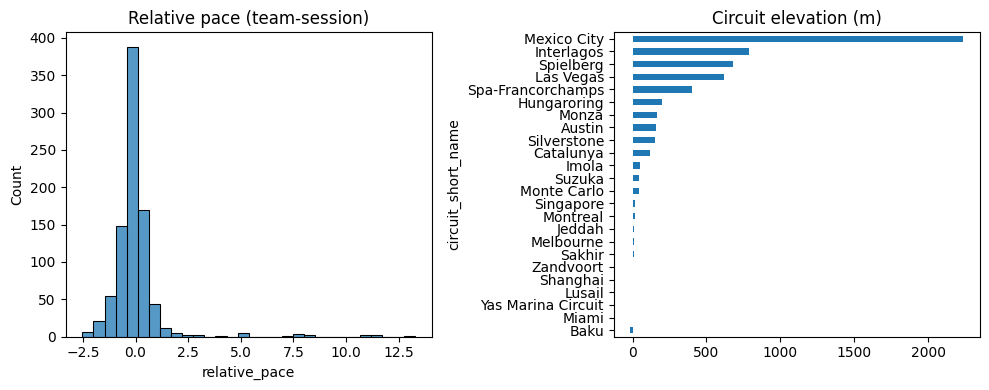

In [47]:
# relative pace + elevation distributions
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df["relative_pace"], bins=30, ax=axes[0])
axes[0].set_title("Relative pace (team-session)")
elev = df.groupby("circuit_short_name")["elevation_m"].first().sort_values()
elev.plot(kind="barh", ax=axes[1])
axes[1].set_title("Circuit elevation (m)")
plt.tight_layout()
plt.show()


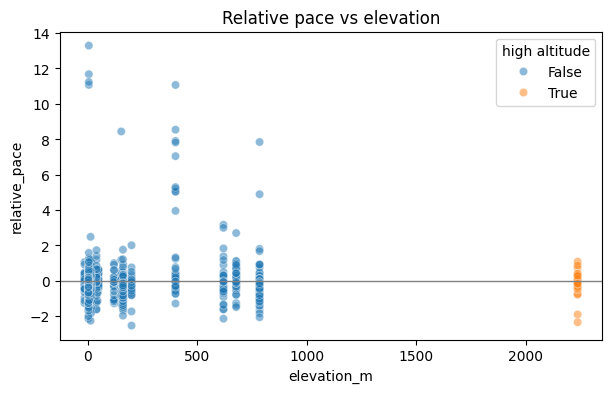

In [48]:
# elevation vs relative pace; hue = high-altitude track flag
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="elevation_m", y="relative_pace", hue="is_mexico_city", alpha=0.5, legend=True)
plt.legend(title="high altitude")
plt.axhline(0, color="gray", lw=1)
plt.title("Relative pace vs elevation")
plt.show()


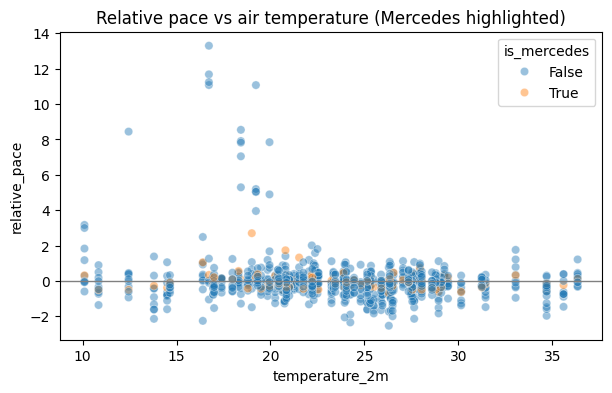

In [49]:
# Mercedes vs others: relative pace vs temperature
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="temperature_2m", y="relative_pace", hue="is_mercedes", alpha=0.45)
plt.axhline(0, color="gray", lw=1)
plt.title("Relative pace vs air temperature (Mercedes highlighted)")
plt.show()


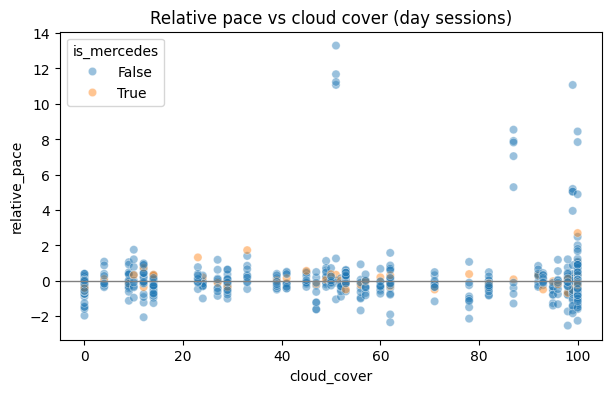

In [50]:
# Cloud cover (daytime sessions only)
day = df[~df["is_night"]]
plt.figure(figsize=(7, 4))
sns.scatterplot(data=day, x="cloud_cover", y="relative_pace", hue="is_mercedes", alpha=0.45)
plt.axhline(0, color="gray", lw=1)
plt.title("Relative pace vs cloud cover (day sessions)")
plt.show()


In [51]:
# Quick correlations among numeric predictors / outcome
df[["relative_pace", "temperature_2m", "cloud_cover", "elevation_m"]].corr().round(3)


,relative_pace,temperature_2m,cloud_cover,elevation_m
relative_pace,1.000,-0.184,0.081,0.017
temperature_2m,-0.184,1.000,-0.143,-0.075
cloud_cover,0.081,-0.143,1.000,0.054
elevation_m,0.017,-0.075,0.054,1.000


**Coverage / basic distributions**

Just checking we have similar amounts of data across years and teams, and that temperature / cloud cover / night races actually vary.

In [52]:
# how much data we have by year / team
print("Rows by year:")
display(df["year"].value_counts().sort_index().to_frame("n_team_sessions"))

print("Rows by team:")
display(df["team_name"].value_counts().sort_values(ascending=False).to_frame("n_team_sessions"))

print("Team x year:")
display(pd.crosstab(df["team_name"], df["year"]))

Rows by year:


,n_team_sessions
year,
2023,280
2024,300
2025,290


Rows by team:


,n_team_sessions
team_name,
Alpine,87
Ferrari,87
Aston Martin,87
McLaren,87
Haas F1 Team,87
Williams,87
Red Bull Racing,87
Mercedes,87
Kick Sauber,59


Team x year:


year,2023,2024,2025
team_name,,,
Alfa Romeo,28,0,0
AlphaTauri,28,0,0
Alpine,28,30,29
Aston Martin,28,30,29
Ferrari,28,30,29
Haas F1 Team,28,30,29
Kick Sauber,0,30,29
McLaren,28,30,29
Mercedes,28,30,29


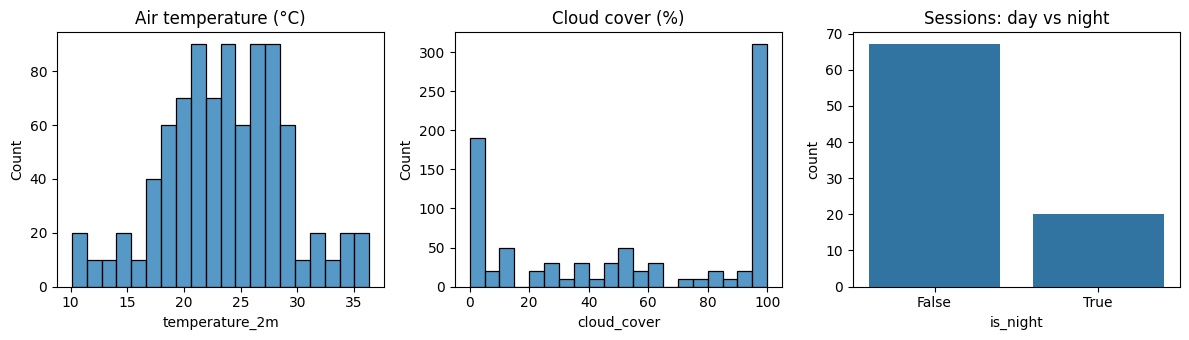

Team-session rows -- day: 670 | night: 200


In [53]:
# temp, cloud cover, day vs night
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
sns.histplot(df["temperature_2m"], bins=20, ax=axes[0])
axes[0].set_title("Air temperature (°C)")
sns.histplot(df["cloud_cover"], bins=20, ax=axes[1])
axes[1].set_title("Cloud cover (%)")
sns.countplot(data=df.drop_duplicates("date_start_est"), x="is_night", ax=axes[2])
axes[2].set_title("Sessions: day vs night")
axes[2].set_xlabel("is_night")
plt.tight_layout()
plt.show()

print("Team-session rows -- day:", (~df["is_night"]).sum(), "| night:", df["is_night"].sum())

**Elevation stuff (for Statement 1)**

Average relative pace at higher vs lower tracks by team, plus a quick check that the elevation pattern isn’t only coming from the highest tracks.

high_altitude,low_alt_mean_rp,high_alt_mean_rp,high_minus_low
team_name,,,
AlphaTauri,0.086719,-2.341417,-2.428136
Alfa Romeo,0.070400,-1.900794,-1.971194
Haas F1 Team,0.016464,-0.460984,-0.477448
Williams,0.013466,-0.377037,-0.390502
Ferrari,0.013451,-0.376631,-0.390083
Racing Bulls,0.006445,-0.180461,-0.186906
Mercedes,0.002084,-0.058343,-0.060427
McLaren,0.000782,-0.021906,-0.022689
Red Bull Racing,-0.002935,0.082194,0.085129


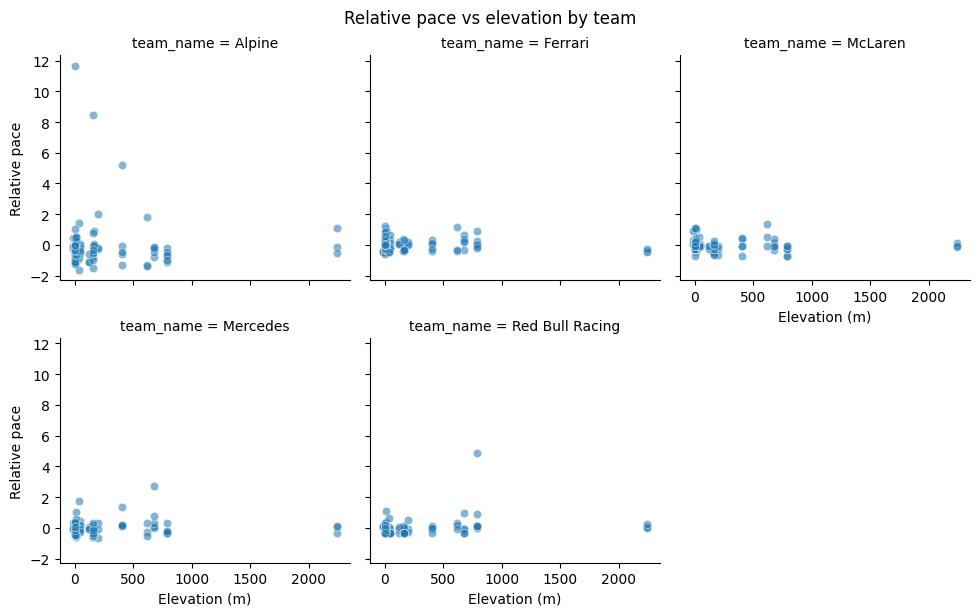

In [54]:
# treat >1000m as "high" for a simple split
df = df.copy()
df["high_altitude"] = df["elevation_m"] > 1000

alt_team = (
    df.groupby(["team_name", "high_altitude"])["relative_pace"]
    .mean()
    .unstack("high_altitude")
    .rename(columns={False: "low_alt_mean_rp", True: "high_alt_mean_rp"})
)
alt_team["high_minus_low"] = alt_team["high_alt_mean_rp"] - alt_team["low_alt_mean_rp"]
display(alt_team.sort_values("high_minus_low"))

# scatter by team for a few teams we care about
focus = ["Ferrari", "Mercedes", "Red Bull Racing", "McLaren", "Alpine"]
focus = [t for t in focus if t in set(df["team_name"])]
g = sns.relplot(
    data=df[df["team_name"].isin(focus)],
    x="elevation_m",
    y="relative_pace",
    col="team_name",
    col_wrap=3,
    kind="scatter",
    alpha=0.55,
    height=3,
    aspect=1.1,
)
g.set_axis_labels("Elevation (m)", "Relative pace")
g.fig.suptitle("Relative pace vs elevation by team", y=1.02)
plt.show()

In [55]:
# does the elevation correlation change if we drop high tracks?
full_corr = df["elevation_m"].corr(df["relative_pace"])
no_high = df.loc[~df["high_altitude"], ["elevation_m", "relative_pace"]].corr().iloc[0, 1]
print(f"corr(elevation, relative_pace) all: {full_corr:.3f}")
print(f"corr(elevation, relative_pace) no high-alt: {no_high:.3f}")
print("high-alt circuits:", sorted(df.loc[df["high_altitude"], "circuit_short_name"].unique()))

corr(elevation, relative_pace) all: 0.017
corr(elevation, relative_pace) no high-alt: 0.065
high-alt circuits: ['Mexico City']


**Temperature / cloud stuff (for Statement 2)**

Mercedes vs everyone else in cooler vs warmer sessions, and same idea for cloud cover during the day. Just descriptive — not the actual regressions yet.

mean    median    n
is_mercedes temp_band                         
False       cool       0.433121 -0.063492  261
            mid       -0.199551 -0.156920  261
            warm      -0.233570 -0.189261  261
True        cool       0.137182  0.066143   29
            mid       -0.025925 -0.058237   29
            warm      -0.111257 -0.150747   29

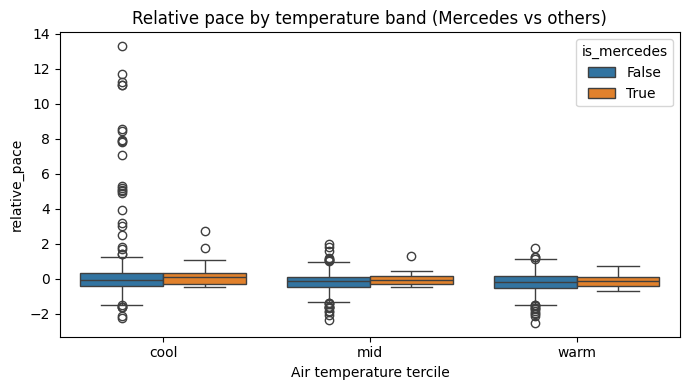

mean    median    n
is_mercedes cloud_band                         
False       clear      -0.108873 -0.103311  207
            mixed       0.328402 -0.106087  216
            cloudy     -0.031600 -0.137068  180
True        clear       0.135352  0.036137   23
            mixed      -0.086427 -0.045148   24
            cloudy      0.135786  0.003953   20

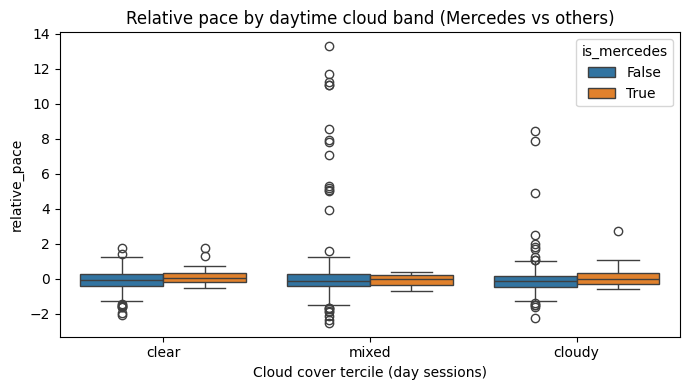

In [56]:
# split temperature into 3 bands, compare Mercedes vs others
df["temp_band"] = pd.qcut(df["temperature_2m"], 3, labels=["cool", "mid", "warm"])
temp_cmp = (
    df.groupby(["is_mercedes", "temp_band"], observed=True)["relative_pace"]
    .agg(mean="mean", median="median", n="count")
)
display(temp_cmp)

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="temp_band", y="relative_pace", hue="is_mercedes")
plt.title("Relative pace by temperature band (Mercedes vs others)")
plt.xlabel("Air temperature tercile")
plt.tight_layout()
plt.show()

# same idea for cloud cover, daytime only
day = df.loc[~df["is_night"]].copy()
day["cloud_band"] = pd.qcut(day["cloud_cover"], 3, labels=["clear", "mixed", "cloudy"])
cloud_cmp = (
    day.groupby(["is_mercedes", "cloud_band"], observed=True)["relative_pace"]
    .agg(mean="mean", median="median", n="count")
)
display(cloud_cmp)

plt.figure(figsize=(7, 4))
sns.boxplot(data=day, x="cloud_band", y="relative_pace", hue="is_mercedes")
plt.title("Relative pace by daytime cloud band (Mercedes vs others)")
plt.xlabel("Cloud cover tercile (day sessions)")
plt.tight_layout()
plt.show()

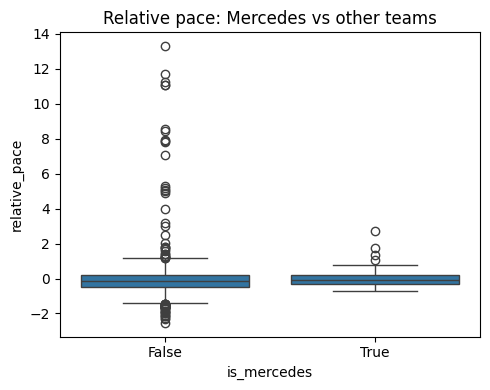

,mean,median,std,count
is_mercedes,,,,
False,2.219028e-17,-0.114918,1.411657,783
True,-6.779379e-18,-0.072479,0.505505,87


In [57]:
# overall Mercedes vs others (means should be near 0 since relative_pace is within-team)
plt.figure(figsize=(5, 4))
sns.boxplot(data=df, x="is_mercedes", y="relative_pace")
plt.title("Relative pace: Mercedes vs other teams")
plt.xlabel("is_mercedes")
plt.tight_layout()
plt.show()

display(df.groupby("is_mercedes")["relative_pace"].agg(["mean", "median", "std", "count"]))

**What we learned from EDA**

- Years look pretty even (~280–300 team-sessions each). Some teams show up under different names across seasons (rebrands), which we’ll need to be careful with for the team dummies.
- `relative_pace` is around 0 on average (by construction). There’s a long right tail from a few really slow weekends.
- Temperature and cloud cover jump around a lot. Most sessions are during the day, so limiting the cloud plot/analysis to daytime makes sense.
- High vs low altitude means differ by team. The elevation correlation also changes a bit if we drop the highest tracks, so the robustness check in Statement 1 seems worth doing.
- The cool/warm and clear/cloudy boxplots don’t scream “Mercedes advantage” on their own. That’s fine — the interaction models are what we’ll use later.
- Still planning to stick with the same research questions above.
